# **Regression - advanced.**
Author: Bartosz Kołacz.

Source: https://www.kaggle.com/datasets/dipam7/student-grade-prediction?resource=download

Dataset: student-mat.csv

This project analyzes a 2008 dataset about the school performance of 395 secondary school students, collected from Portuguese schools in a mathematics course.

# **1. Imports and data upload**

Let's begin with adding necessary libraries and with loading of the dataset from student-mat.csv.

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

df = pd.read_csv('student-mat.csv')
df.head(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# **2. Introduction**

Data dictionary:

| Column name | Data type | Description |
|---|---|---|
|G1 | int | Grade from first period |
|G2 | int | Grade from second period |
|G3 | int | Final grade in the mathematics course |
|failures | int | Number of failed subjects |
|absences | int | Number of student's absences during the school year. |
|Medu | int | Mother's education |
|Fedu | int | Father's education |
|higher | boolean | Student's desire to study and contiune education |
|age | int | Participant age |
|goout | int | Going out with friends (numeric: from 1 - very low to 5 - very high) |
|freetime | int | Free time after school (numeric: from 1 - very low to 5 - very high)
|studytime | int | Weekly study time (numeric: 1: <2 hours, 2: 2 to 5 hours, 3: 5 to 10 hours, 4: >10 hours)

I chose, from the dataset 11, in my opinion, the most important columns with data for regression. In my later work, I will focus on analysing them.

G3 is the target variable, that my regression model will try to predict. It is important to validate the predictions.

What is important: portugeese school system use grades in scale 0 - 20.

# **3. Dataset on graphs**

Let's have a look on collected data on charts. I began my analysis with sight at the distribution of key variables.

* Age distribution

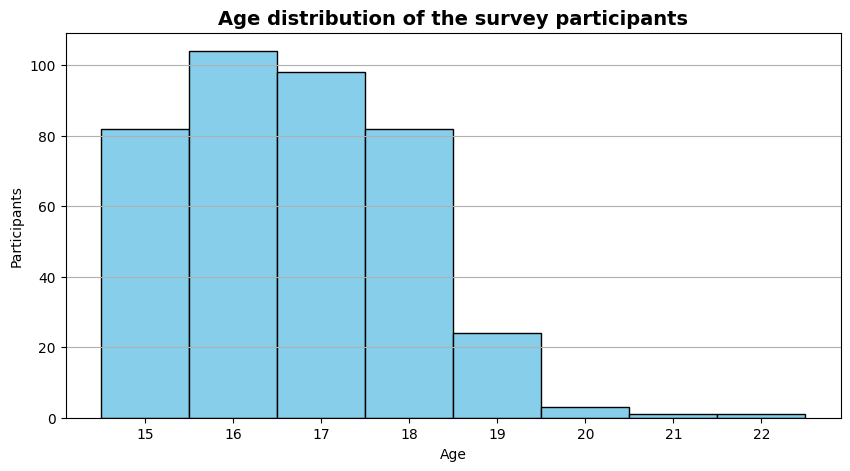

In [92]:
plt.figure(figsize=(10, 5))
min_age = int(df["age"].min())
max_age = int(df["age"].max())
bins = np.arange(min_age, max_age + 2)
plt.hist(df["age"], bins=bins, edgecolor="black", color="skyblue", align="left")
plt.title("Age distribution of the survey participants", fontsize=14, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Participants")
plt.xticks(range(min_age, max_age + 1))
plt.grid(axis="y", alpha=1)
plt.show()

* Responders gender

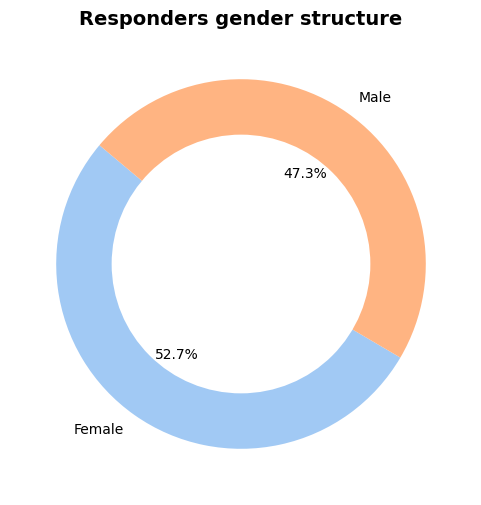

In [93]:
df_temp = df.copy()
df_temp["sex"] = df_temp["sex"].replace({"F": "Female", "M": "Male"})
gender_counts = df_temp["sex"].value_counts()
colors = sns.color_palette("pastel", len(gender_counts))
plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
)
centre_circle = plt.Circle((0, 0), 0.70, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title("Responders gender structure", fontsize=14, fontweight="bold")
plt.show()

* Parents education

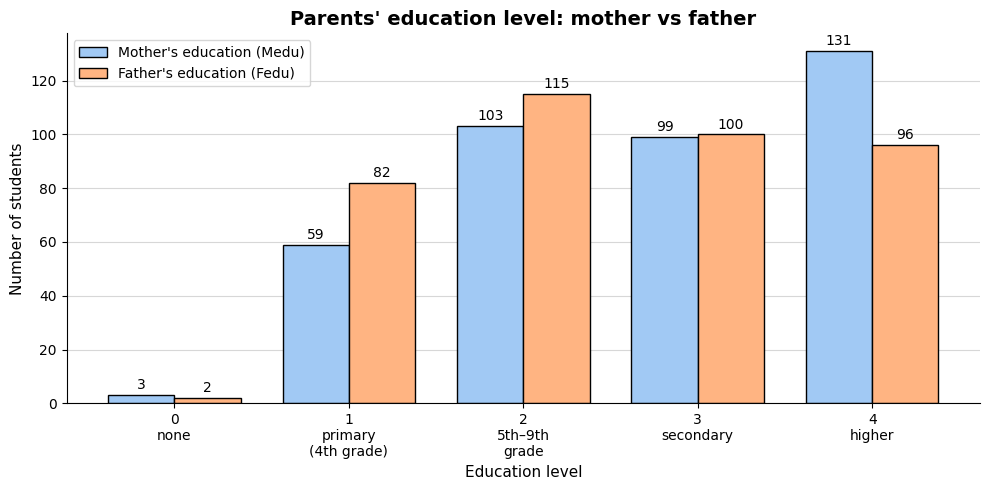

In [94]:
levels = [0, 1, 2, 3, 4]
medu_counts = df['Medu'].value_counts().reindex(levels, fill_value=0)
fedu_counts = df['Fedu'].value_counts().reindex(levels, fill_value=0)

x = np.arange(len(levels))
width = 0.38
colors = sns.color_palette("pastel", 2)
fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width/2, medu_counts.values, width,
    label="Mother's education (Medu)",
    color=colors[0], edgecolor='black'
)
bars2 = ax.bar(
    x + width/2, fedu_counts.values, width,
    label="Father's education (Fedu)",
    color=colors[1], edgecolor='black'
)

ax.set_xticks(x)
ax.set_xticklabels([
    '0\nnone',
    '1\nprimary\n(4th grade)',
    '2\n5th–9th\ngrade',
    '3\nsecondary',
    '4\nhigher'
], fontsize=10)

ax.set_xlabel('Education level', fontsize=11)
ax.set_ylabel('Number of students', fontsize=11)

ax.set_title("Parents' education level: mother vs father", fontsize=14, fontweight='bold')
ax.legend(frameon=True)
ax.bar_label(bars1, padding=2)
ax.bar_label(bars2, padding=2)
ax.set_axisbelow(True)
ax.grid(axis='y', linestyle='-', alpha=0.5)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

* Desire to continue education

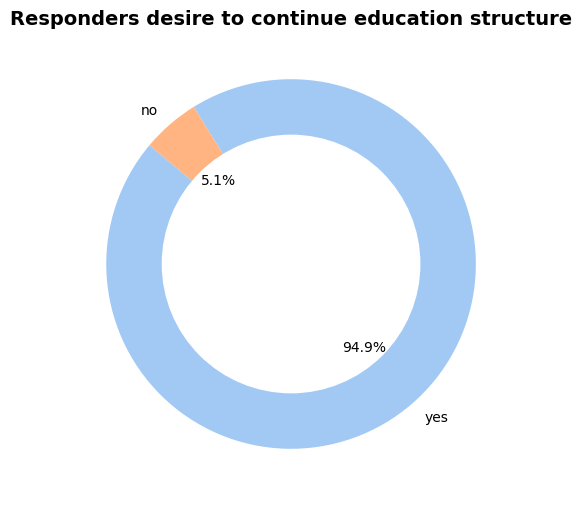

In [95]:
higher_count = df["higher"].value_counts()
colors = sns.color_palette("pastel", len(higher_count))
plt.figure(figsize=(6, 6))
plt.pie(
    higher_count,
    labels=higher_count.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
)
centre_circle = plt.Circle((0, 0), 0.70, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title("Responders desire to continue education structure", fontsize=14, fontweight="bold")
plt.show()

* Final grade distribution

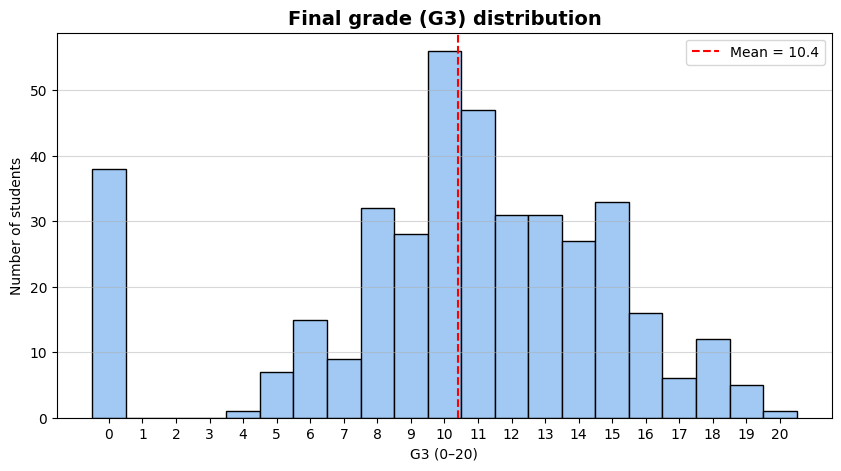

In [96]:
plt.figure(figsize=(10, 5))
bins = np.arange(0, 22) - 0.5
plt.hist(df['G3'], bins=bins, edgecolor='black', color=sns.color_palette("pastel")[0])
plt.axvline(df['G3'].mean(), color='red', linestyle='--', label=f"Mean = {df['G3'].mean():.1f}")
plt.title("Final grade (G3) distribution", fontsize=14, fontweight='bold')
plt.xlabel("G3 (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21))
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

Above, we can see short summary of data in each column. I observed that:

1.   The dataset is focused on students from primary school (classes: 1-9) and high school (classes: 10-12). There is a very few records from students in higher education (age > 20).
2.   Participants gender is evenly distributed.
3.   Portugese society is generally well educated, most of participants parents have good education.
4.   Almost every student desire to continue education.
5.   Mean of the final grades is 10,4.


# **4. Data analysis**

Let's begin with investigation, how marks from each period (G1 and G2) impacts on final grade G3.



*  **Linear regression**



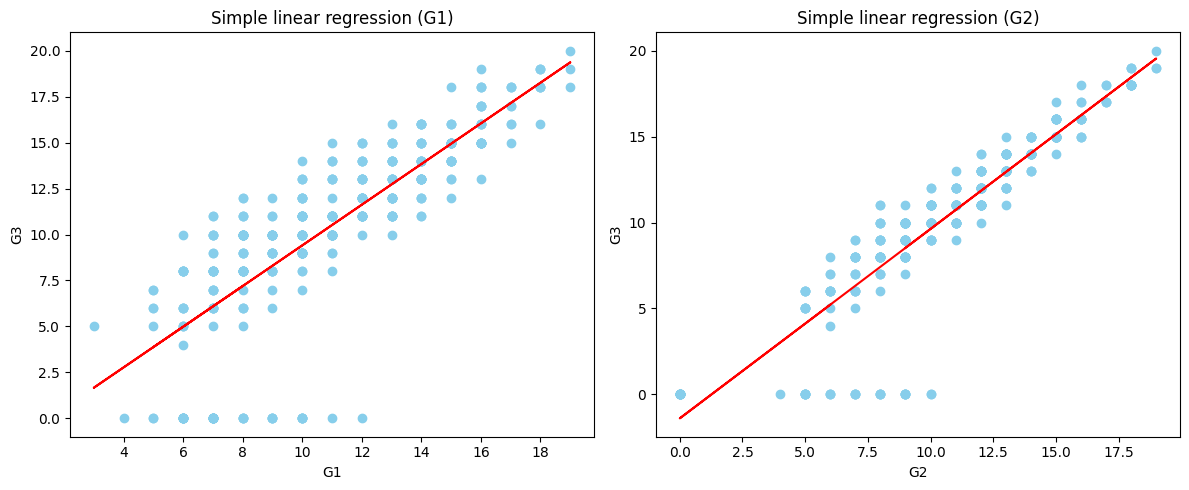

In [97]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
y = df['G3']

# G1 to G3 linear regression
X_g1 = df[['G1']]
model_g1 = LinearRegression()
model_g1.fit(X_g1, y)

ax1.scatter(X_g1, y, color='skyblue')
ax1.plot(X_g1, model_g1.predict(X_g1), color='red')
ax1.set_title('Simple linear regression (G1)')
ax1.set_xlabel('G1')
ax1.set_ylabel('G3')

# G2 to G3 linear regression
X_g2 = df[['G2']]
model_g2 = LinearRegression()
model_g2.fit(X_g2, y)

ax2.scatter(X_g2, y, color='skyblue')
ax2.plot(X_g2, model_g2.predict(X_g2), color='red')
ax2.set_title('Simple linear regression (G2)')
ax2.set_xlabel('G2')
ax2.set_ylabel('G3')

plt.tight_layout()
plt.show()

In [98]:
prediction_g1 = model_g1.predict(X_g1)
print('G1 to G3:')
print("Intercept: ", model_g1.intercept_)
print("Coefficients: ", model_g1.coef_)
print("Score (R^2): ", model_g1.score(X_g1, y))

G1 to G3:
Intercept:  -1.6528038288004634
Coefficients:  [1.10625609]
Score (R^2):  0.6423508460522701


In [99]:
prediction_g2 = model_g2.predict(X_g2)
print('G2 to G3:')
print("Intercept: ", model_g2.intercept_)
print("Coefficients: ", model_g2.coef_)
print("Score (R^2): ", model_g2.score(X_g2, y))

G2 to G3:
Intercept:  -1.3927582066452384
Coefficients:  [1.10211236]
Score (R^2):  0.818786078004268


As we can see above, the relationship between G2 and G3 is stronger (R2 = 0.82) than between G1 and G3 (R2 = 0.64), which means that the grade from the second period predicts the final grade more accurately than the grade from the first period. Coefficients are nearly equal, that meas the tilts of the linear functions are almost the same.

* **Polynomial regression**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


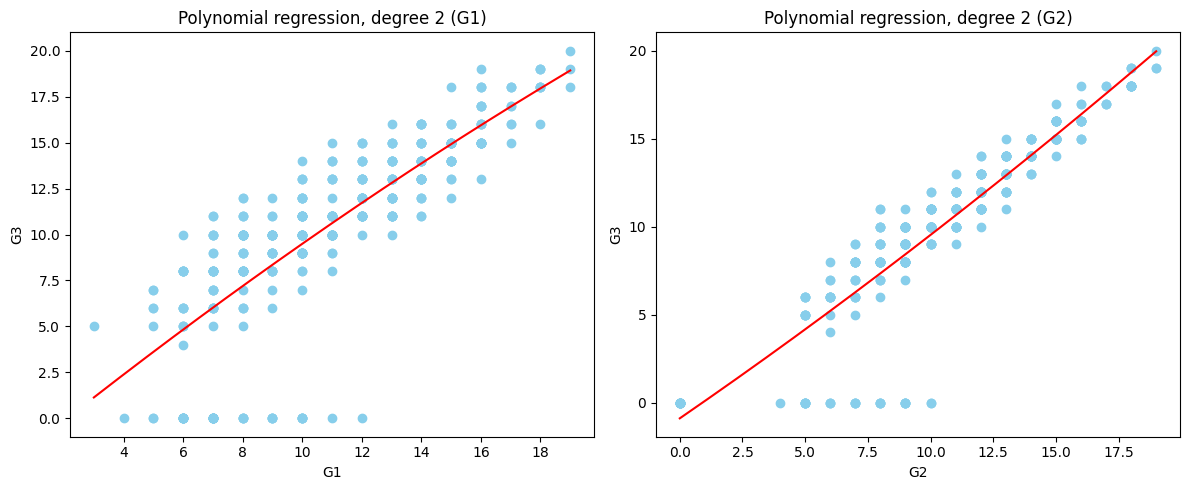

In [100]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
y = df['G3']
poly = PolynomialFeatures(degree=2)

# G1 to G3 polynomial regression
X_g1 = df[['G1']]
X_g1_poly = poly.fit_transform(X_g1)
model_g1 = LinearRegression()
model_g1.fit(X_g1_poly, y)

X_g1_line = np.linspace(X_g1['G1'].min(), X_g1['G1'].max(), 200).reshape(-1, 1)

ax1.scatter(X_g1, y, color='skyblue')
ax1.plot(X_g1_line, model_g1.predict(poly.transform(X_g1_line)), color='red')
ax1.set_title('Polynomial regression, degree 2 (G1)')
ax1.set_xlabel('G1')
ax1.set_ylabel('G3')

# G2 to G3 polynomial regression
X_g2 = df[['G2']]
X_g2_poly = poly.fit_transform(X_g2)
model_g2 = LinearRegression()
model_g2.fit(X_g2_poly, y)

X_g2_line = np.linspace(X_g2['G2'].min(), X_g2['G2'].max(), 200).reshape(-1, 1)

ax2.scatter(X_g2, y, color='skyblue')
ax2.plot(X_g2_line, model_g2.predict(poly.transform(X_g2_line)), color='red')
ax2.set_title('Polynomial regression, degree 2 (G2)')
ax2.set_xlabel('G2')
ax2.set_ylabel('G3')

plt.tight_layout()
plt.show()

In [101]:
print('G1 to G3:')
print('Intercept: ', model_g1.intercept_)
print('Coefficients: ', model_g1.coef_)
print('Score (R^2): ', model_g1.score(X_g1_poly, y))

G1 to G3:
Intercept:  -2.7218014360331733
Coefficients:  [ 0.          1.31342143 -0.00916161]
Score (R^2):  0.6429522983997928


In [102]:
print('G2 to G3:')
print('Intercept: ', model_g2.intercept_)
print('Coefficients: ', model_g2.coef_)
print('Score (R^2): ', model_g2.score(X_g2_poly, y))

G2 to G3:
Intercept:  -0.878096058061514
Coefficients:  [0.         0.97980219 0.0061734 ]
Score (R^2):  0.81966339780047


I was quite surprised with results of the polinomial regression with 2 degree. Usage of the quadratic term did not increse accuracy of my prediction, the change is almost imperceptible (R2 for G1 increased only for 0.0006 and R2 for G2 increased only 0.0009). I assume that increasing polinomial degree for that dataset will not help to achieve better results (I will check that in my later work).

Funfact: I was also shocked by the shape of a quadratic function on the charts above. In the first place, I thought I messed something up with the code, because it was almost the same as for linear regression. Then I took my physical ruler from the pencilcase to check whether the line is curved. It was indeed.

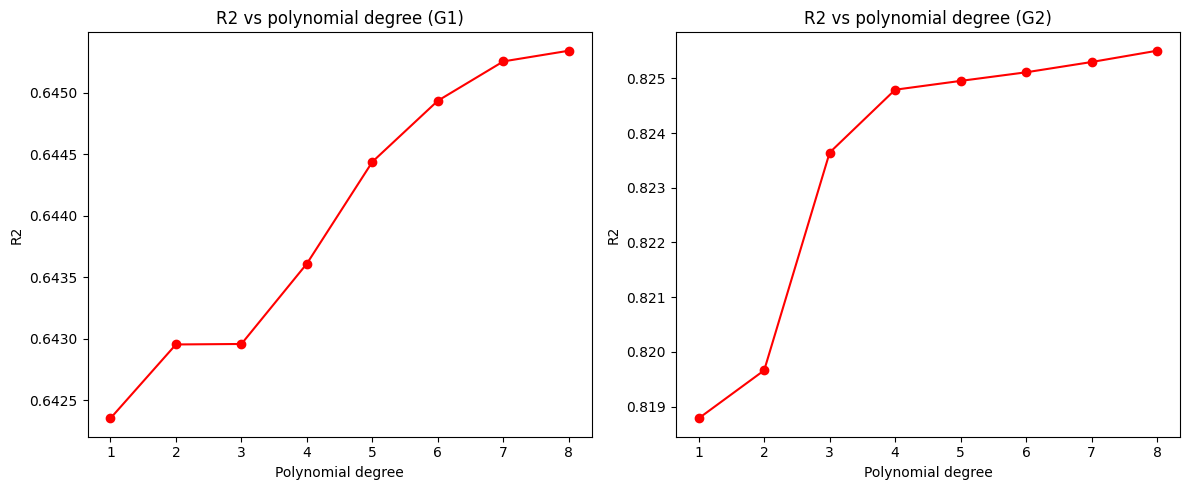

In [103]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
y = df['G3'].values

# G1 to G3
X = df[['G1']].values
r2_g1 = []

for order in range(1, 9):
    poly = PolynomialFeatures(order, include_bias=False)
    X_order = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_order, y)
    r2_g1.append(r2_score(y, model.predict(X_order)))

ax1.plot(range(1, 9), r2_g1, color='red', marker='o')
ax1.set_title('R2 vs polynomial degree (G1)')
ax1.set_xlabel('Polynomial degree')
ax1.set_ylabel('R2')

# G2 to G3
X = df[['G2']].values
r2_g2 = []

for order in range(1, 9):
    poly = PolynomialFeatures(order, include_bias=False)
    X_order = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_order, y)
    r2_g2.append(r2_score(y, model.predict(X_order)))

ax2.plot(range(1, 9), r2_g2, color='red', marker='o')
ax2.set_title('R2 vs polynomial degree (G2)')
ax2.set_xlabel('Polynomial degree')
ax2.set_ylabel('R2')

plt.tight_layout()
plt.show()

The R2 slightly increases with the growth of polynomial degree. Unfortunatelly, the increase is not satisfying. Higher degree models do not explain the final grade much better than a simple straight line. However, G2 still predicts G3 better then G1.

* **Absences vs final grade**

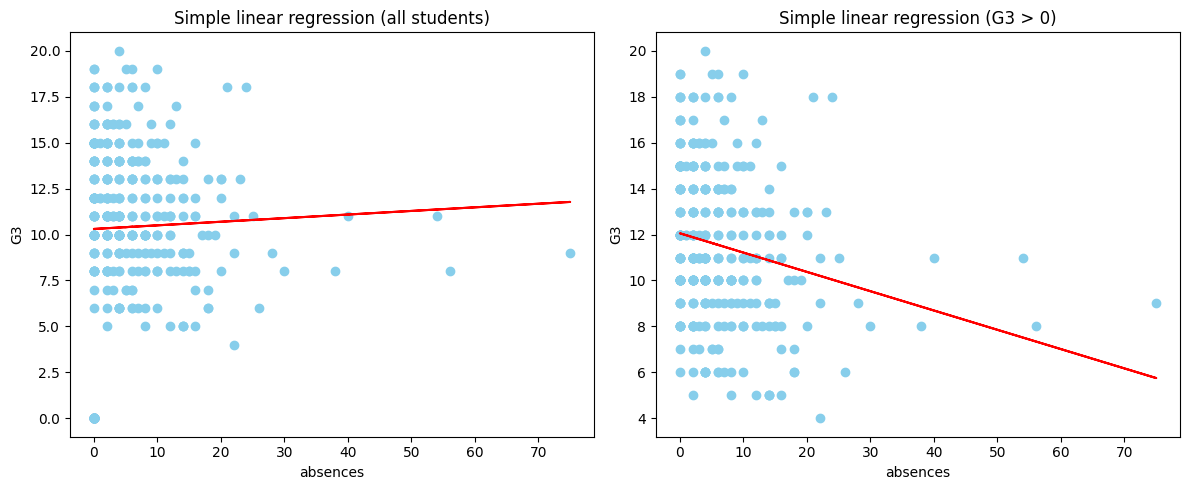

All students:
Intercept:  10.30326664345914
Coefficients:  [0.01960518]
Score (R^2):  0.0011728786634828126

Students with G3 > 0:
Intercept:  12.054532993860953
Coefficients:  [-0.08402141]
Score (R^2):  0.0454237712137745


In [104]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# All students: absences to G3
X_all = df[['absences']]
y_all = df['G3']
model_all = LinearRegression()
model_all.fit(X_all, y_all)

ax1.scatter(X_all, y_all, color='skyblue')
ax1.plot(X_all, model_all.predict(X_all), color='red')
ax1.set_title('Simple linear regression (all students)')
ax1.set_xlabel('absences')
ax1.set_ylabel('G3')

# Students with G3 > 0: absences to G3
df_nz = df[df['G3'] > 0]
X_nz = df_nz[['absences']]
y_nz = df_nz['G3']
model_nz = LinearRegression()
model_nz.fit(X_nz, y_nz)

ax2.scatter(X_nz, y_nz, color='skyblue')
ax2.plot(X_nz, model_nz.predict(X_nz), color='red')
ax2.set_title('Simple linear regression (G3 > 0)')
ax2.set_xlabel('absences')
ax2.set_ylabel('G3')

plt.tight_layout()
plt.show()

print('All students:')
print('Intercept: ', model_all.intercept_)
print('Coefficients: ', model_all.coef_)
print('Score (R^2): ', model_all.score(X_all, y_all))
print()
print('Students with G3 > 0:')
print('Intercept: ', model_nz.intercept_)
print('Coefficients: ', model_nz.coef_)
print('Score (R^2): ', model_nz.score(X_nz, y_nz))

When creating above shown chart, I found out highly misleading, and shocking infromation: linear regression sugested that the more absences student posses the better final grade. That fact was highly unlogical. Then I found out that the chart was messed up by student that were probably not graded (final grade 0 and 0 absence). After removing them from the dataset, the shape of the regression is completely different: more absences are linked with lower final grades

*   **Failures and G2 vs G3**

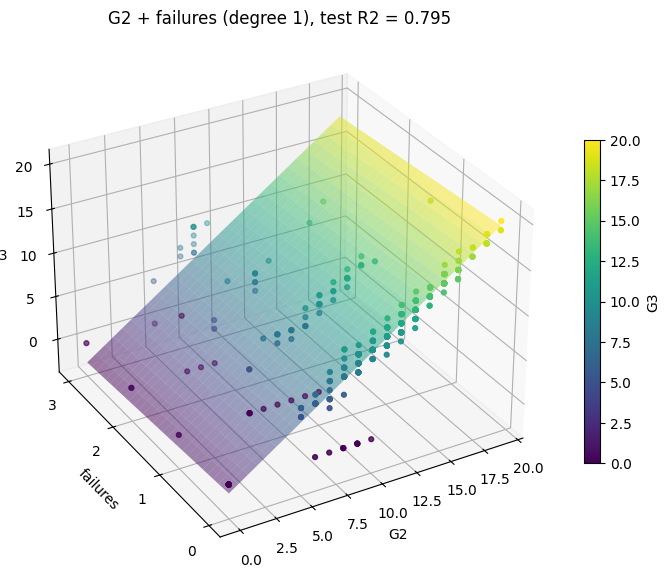

In [105]:
x_col, y_col = 'G2', 'failures'

X = df[[x_col, y_col]]
y = df['G3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
test_r2 = model.score(X_test, y_test)

x_grid, y_grid = np.meshgrid(
    np.linspace(df[x_col].min(), df[x_col].max(), 30),
    np.linspace(df[y_col].min(), df[y_col].max(), 30)
)
grid = pd.DataFrame({x_col: x_grid.ravel(), y_col: y_grid.ravel()})
z_grid = model.predict(grid).reshape(x_grid.shape)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(x_grid, y_grid, z_grid, cmap='viridis', alpha=0.5)
sc = ax.scatter(df[x_col], df[y_col], y, c=y, cmap='viridis', s=12)

ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
ax.set_zlabel('G3')
ax.set_yticks([0, 1, 2, 3])   # failures to liczby calkowite 0-3
ax.set_title(f'{x_col} + {y_col} (degree 1), test R2 = {test_r2:.3f}')
fig.colorbar(sc, ax=ax, shrink=0.6, label='G3')
ax.view_init(elev=30, azim=-120)

plt.show()

The regression plane is tilted mainly along the G2 axis. I observed, that the chart clearly shows tendency that the students with no failures has, and will have better grades, than a students with more failures.

*   **Impact of G1 and G2** (multiple regression)

So far, I used only one or two variables to predict the final grade. Now I will use multiple linear regression with all 11 selected variables (model A) and compare it with a model without the earlier grades G1 and G2

In [106]:
df_m = df.copy()
df_m['higher'] = df_m['higher'].map({'yes': 1, 'no': 0})

features_all = ['G1', 'G2', 'failures', 'absences', 'Medu', 'Fedu',
                'higher', 'age', 'goout', 'freetime', 'studytime']
features_context = [c for c in features_all if c not in ['G1', 'G2']]

y = df_m['G3']

# Model A: all variables
X = df_m[features_all]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model_a = LinearRegression()
model_a.fit(X_train, y_train)

print('Model A: all variables')
print('R2 train:', model_a.score(X_train, y_train))
print('R2 test: ', model_a.score(X_test, y_test))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, model_a.predict(X_test))))
print()

# Model B: without G1 and G2
X = df_m[features_context]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model_b = LinearRegression()
model_b.fit(X_train, y_train)

print('Model B: without G1 and G2')
print('R2 train:', model_b.score(X_train, y_train))
print('R2 test: ', model_b.score(X_test, y_test))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, model_b.predict(X_test))))

Model A: all variables
R2 train: 0.8441603192317454
R2 test:  0.8007680785457131
RMSE test: 2.0927323601984216

Model B: without G1 and G2
R2 train: 0.18450938090875046
R2 test:  0.12756875059158346
RMSE test: 4.379250968887572


R2 on Model A and Model B is terryingly diffrent. That fact shows us that G1 and G2 are the most important factors in grade predictions.

* **Ridge**

Ridge is a linear regression with a penalty for large coefficients, which makes the model less sensitive to noise and to correlated variables. The strength of the penalty is controlled by alpha

In [107]:
X = df_m[features_context]
y = df_m['G3']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

alphas = np.logspace(-2, 3, 30)
coefs = []
r2_test = []

for alpha in alphas:
    m = Ridge(alpha=alpha)
    m.fit(X_train_s, y_train)
    coefs.append(m.coef_)
    r2_test.append(m.score(X_test_s, y_test))
coefs = np.array(coefs)

ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_s, y_train)
best_alpha = ridge_cv.alpha_

ols = LinearRegression()
ols.fit(X_train_s, y_train)

LinearRegression()

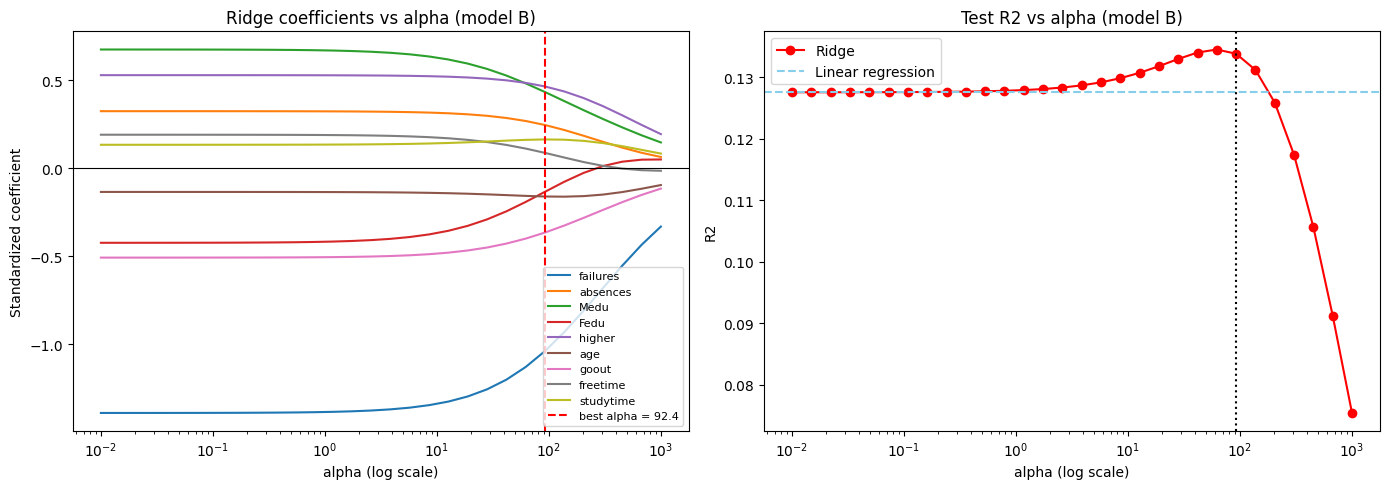

In [108]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for i, name in enumerate(features_context):
    ax1.plot(alphas, coefs[:, i], label=name)
ax1.axhline(0, color='black', linewidth=0.8)
ax1.axvline(best_alpha, color='red', linestyle='--', label=f'best alpha = {best_alpha:.1f}')
ax1.set_xscale('log')
ax1.set_title('Ridge coefficients vs alpha (model B)')
ax1.set_xlabel('alpha (log scale)')
ax1.set_ylabel('Standardized coefficient')
ax1.legend(fontsize=8)
ax2.plot(alphas, r2_test, color='red', marker='o', label='Ridge')
ax2.axhline(ols.score(X_test_s, y_test), color='skyblue', linestyle='--', label='Linear regression')
ax2.axvline(best_alpha, color='black', linestyle=':')
ax2.set_xscale('log')
ax2.set_title('Test R2 vs alpha (model B)')
ax2.set_xlabel('alpha (log scale)')
ax2.set_ylabel('R2')
ax2.legend()

plt.tight_layout()
plt.show()

I used Ridge regression on model B, and the left chart shows that the bigger the alpha, the closer to zero all coefficients are, while failures stays the most important variable. The right chart shows that a moderate alpha (about 92) gives a slightly better test R2 than the normal regression (0.134 instead of 0.128).

# **5. Summary**

The grade from the second period (G2) is by far the best predictor.

Neither the polynomial regression nor the extra variables (failures and others) improved the results in a meaningful way. Without G1 and G2 collected data shows vey small impact on actuall grade. Ridge regression made the coefficients more stable but did not change this conclusion.

The main limitation is the small size of the dataset.
